# Forecast-start surface-variable bias and spread (PRECT, TREFHT)

Ensemble bias, spread, t-test significance, and global PCC/RMSE of PRECT (vs GPCP) or TREFHT (vs ERA5) on selected dates of the January forecasts, for each experiment. Products are cached per experiment and date under `data/analysis_lnd_model_evaluation/surface_variables/`; figures (bias top, spread bottom) go to `figure/analysis_lnd_model_evaluation/surface_variables/`.

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")   # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")   # land mask, soil-layer thickness
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
WORKFLOW_NAME = "analysis_lnd_model_evaluation"

VARIABLE = "PRECT"  # "PRECT" or "TREFHT"
MODEL_KEYS = ["CTRLEN10", "CAPTEN10", "DARTEN20", "DARTEN40"]
TARGET_DATES = ["2012-01-01", "2012-01-05", "2012-01-10", "2012-01-15"]
MASK_LAND = False
CONFIDENCE_LEVEL = 0.05
RUN_PROCESSING = True
RUN_PLOTTING = True
FORCE_COMPUTE = False
FIGURE_DPI = 200

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
WORKFLOW_DATA_DIR, WORKFLOW_FIGURE_DIR = workflow_output_dirs(WORKFLOW_NAME, output_root=DIAGNOSTIC_OUTPUT_ROOT)

import numpy as np
import xarray as xr
import cmocean
from util.initial_lnd_surface_variables import SurfaceVarDiffProcessor, SurfaceVarDiffPlotter

VARIABLE_CONFIGS = {
    "PRECT": {"obs_key": "GPCP", "obs_variable": "PRECT", "model_scale": 86400e3,   # m s-1 -> mm day-1
              "obs_scale": 1.0, "bias_levels": [-8, -5, -3, -2, -1, -0.1, 0, 0.1, 1, 2, 3, 5, 8],
              "spread_levels": np.linspace(0, 2, 11)},
    "TREFHT": {"obs_key": "ERA5", "obs_variable": "TREFHT", "model_scale": 1.0, "obs_scale": 1.0,
               "bias_levels": [-8, -5, -3, -2, -1, -0.5, 0, 0.5, 1, 2, 3, 5, 8],
               "spread_levels": np.linspace(0, 5, 11)},
}
CASE_NAMES = {key: f"{key}_15day_F20TR_ne30pg2_r05_IcoswISC30E3r5_compy" for key in MODEL_KEYS}
ENSEMBLE_SIZES = {"CTRLEN10": 10, "CAPTEN10": 10, "DARTEN20": 20, "DARTEN40": 40}
DATASETS = {
    # member files: <case>/EN##/archive/post/atm/180x360_aave/ts/daily/<VAR>.EN##.<year>.nc
    key: {"path": str(INPUT_DATA_ROOT / CASE_NAMES[key]),
          "template": f"%(ensemble)s/archive/post/atm/180x360_aave/ts/daily/{VARIABLE}.%(ensemble)s.%(year)s.nc",
          "frequency": "daily", "nens": ENSEMBLE_SIZES[key]}
    for key in MODEL_KEYS
}
DATASETS["GPCP"] = {"path": str(OBSERVATION_ROOT / "GPCP/daily"),
                    "template": "PRECT.daily.%(year)s.nc", "frequency": "daily", "nens": 1}
DATASETS["ERA5"] = {"path": str(OBSERVATION_ROOT / "ERA5/6hourly"),
                    "template": "ERA5.6hourly.en00.TREFHT.%(year)s01-%(year)s12.nc", "frequency": "6hourly", "nens": 1}

cfg = VARIABLE_CONFIGS[VARIABLE]
PROCESSED_DIR = WORKFLOW_DATA_DIR / "surface_variables"
PROCESSED_FIGURE_DIR = WORKFLOW_FIGURE_DIR / "surface_variables"
for folder in (PROCESSED_DIR, PROCESSED_FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def cache_is_valid(path):
    """Reuse a cached product only if it holds the fields (old empty files are rebuilt)."""
    if not path.is_file():
        return False
    with xr.open_dataset(path) as ds:
        return {"bias", "model_std", "sig_mask"} <= set(ds.data_vars)


def processed_path(model_key, target_date):
    return PROCESSED_DIR / f"{VARIABLE}_bias_spread_{model_key}_vs_{cfg['obs_key']}_{target_date.replace('-', '')}.nc"

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 3. Process and cache

In [3]:
if RUN_PROCESSING:
    processor = SurfaceVarDiffProcessor(
        data_dict=DATASETS, variable=VARIABLE, obs_variable=cfg["obs_variable"],
        fscale=cfg["model_scale"], obs_fscale=cfg["obs_scale"],
        landmask_file=str(LAND_SUPPORT_DIR / "landmask_1x1.nc"), landmask_var="landmask",
        mask_land=MASK_LAND, confidence_level=CONFIDENCE_LEVEL,
    )
    for model_key in MODEL_KEYS:
        for target_date in TARGET_DATES:
            target = processed_path(model_key, target_date)
            if cache_is_valid(target) and not FORCE_COMPUTE:
                print(f"[REUSE] {target}")
                continue
            processor.process_and_save(model_key=model_key, obs_key=cfg["obs_key"],
                                       target_date=target_date, out_nc=str(target))

sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CTRLEN10_vs_GPCP_20120101.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CTRLEN10_vs_GPCP_20120105.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CTRLEN10_vs_GPCP_20120110.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CTRLEN10_vs_GPCP_20120115.nc


sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CAPTEN10_vs_GPCP_20120101.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CAPTEN10_vs_GPCP_20120105.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CAPTEN10_vs_GPCP_20120110.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_CAPTEN10_vs_GPCP_20120115.nc


sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN20_vs_GPCP_20120101.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN20_vs_GPCP_20120105.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN20_vs_GPCP_20120110.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN20_vs_GPCP_20120115.nc


[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN40_vs_GPCP_20120101.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN40_vs_GPCP_20120105.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN40_vs_GPCP_20120110.nc
[REUSE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_spread_DARTEN40_vs_GPCP_20120115.nc


sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


## 4. Plot

sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found
sh: getfattr: command not found


sh: getfattr: command not found


sh: getfattr: command not found


sh: getfattr: command not found


sh: getfattr: command not found


...

sh: getfattr: command not found


sh: getfattr: command not found


sh: getfattr: command not found


sh: getfattr: command not found


[SAVED] Figure saved to: /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/analysis_lnd_model_evaluation/surface_variables/PRECT_bias_stddev_vs_GPCP_20120115.pdf


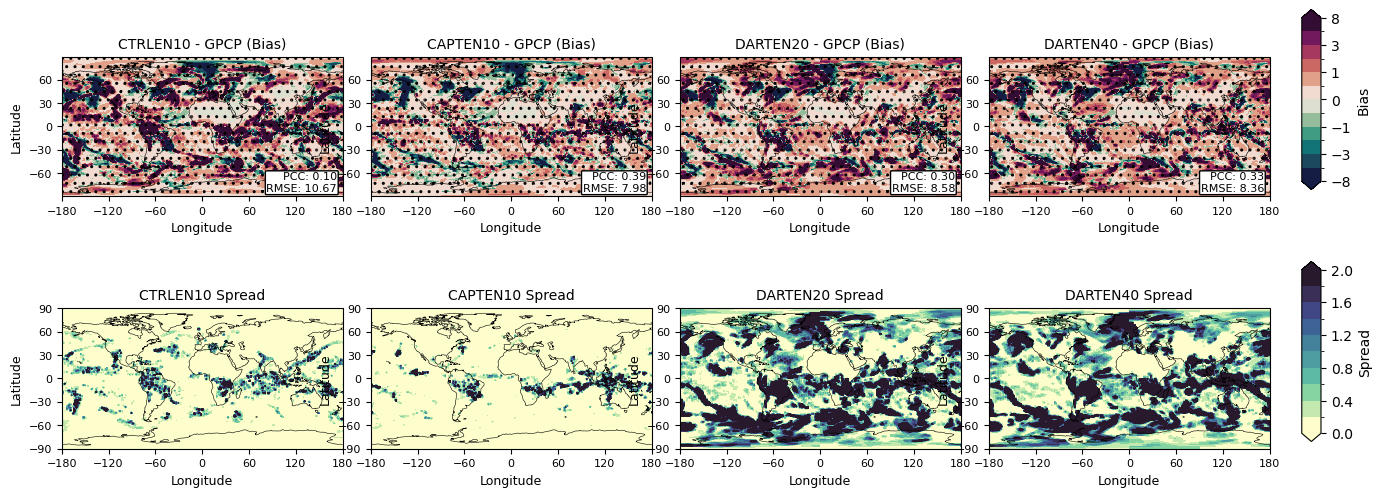

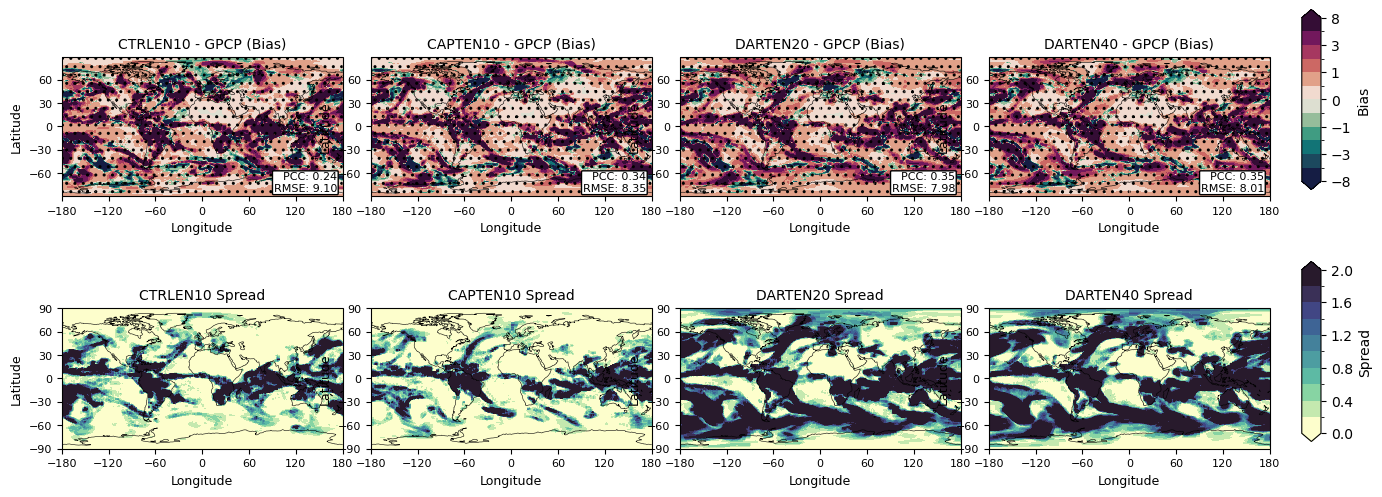

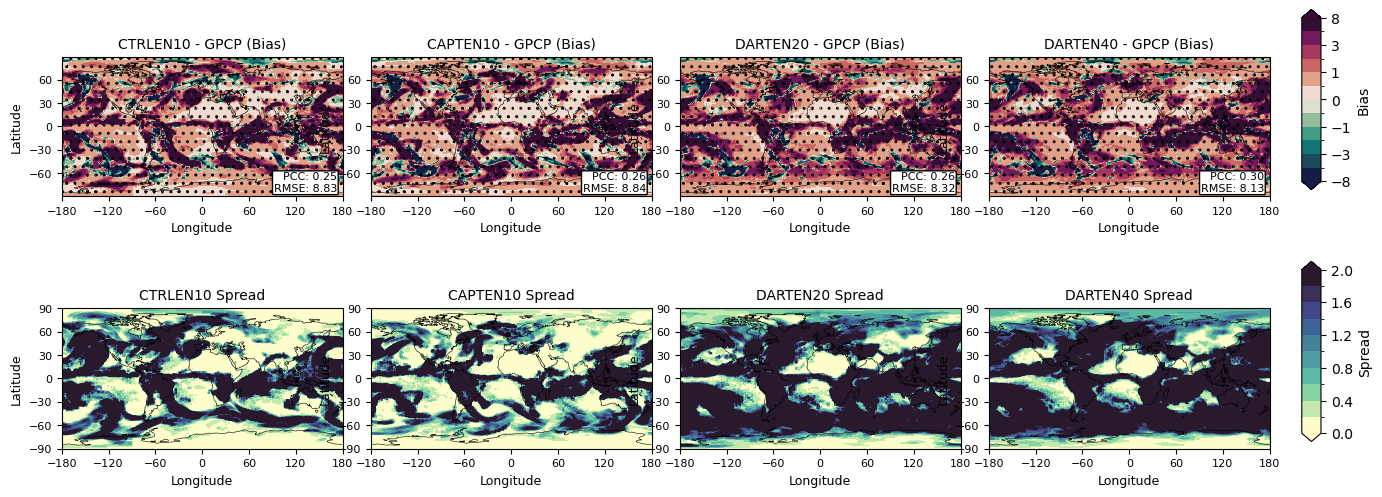

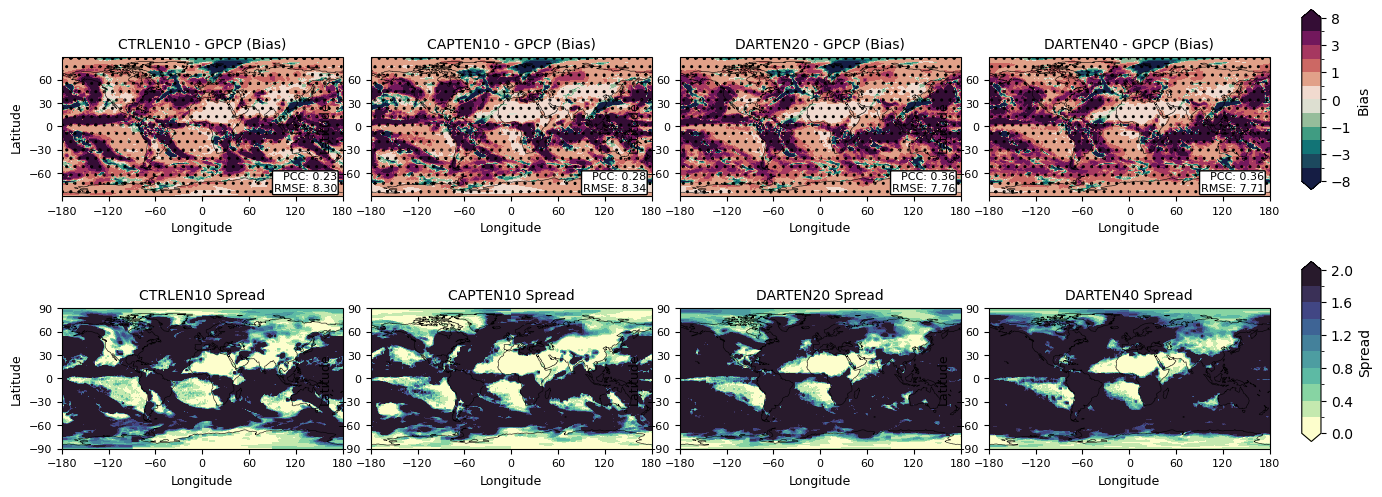

In [4]:
if RUN_PLOTTING:
    plotter = SurfaceVarDiffPlotter(confidence_level=CONFIDENCE_LEVEL)
    for target_date in TARGET_DATES:
        files = [processed_path(key, target_date) for key in MODEL_KEYS]
        missing = [path for path in files if not cache_is_valid(path)]
        if missing:
            raise FileNotFoundError("Missing processed files:\n" + "\n".join(map(str, missing)))
        output = PROCESSED_FIGURE_DIR / f"{VARIABLE}_bias_stddev_vs_{cfg['obs_key']}_{target_date.replace('-', '')}.pdf"
        plotter.plot_bias_and_stddev_multi_panel(
            processed_files=[str(path) for path in files], model_labels=MODEL_KEYS,
            bias_levels=cfg["bias_levels"], spread_levels=cfg["spread_levels"],
            cmap_bias=cmocean.cm.curl, cmap_std=cmocean.cm.deep,
            figsize=(4 * len(MODEL_KEYS), 6), savepath=str(output), fontz=10, dpi=FIGURE_DPI,
        )